# Planta Física: genetic algorithms through four decisions

MA2015.202 · March 2025 · One cumulative notebook.

We explain the supplied model, follow one generation and compare two small configurations. Keep your team's calculations, code and interpretation in this notebook.

Lucas Alejandro Barkovich Carreño   A01667826

Jose Miguel Badillo Villegas A01660209

## 1. We define the problem

We allocate a fraction of treated water to each building to reduce potable-water use. We use aggregate March 2025 demands: Aulas 1 = 847, Biblioteca = 462, Cedetec = 284.21 and Aulas 2 = 683 m³. We retain this order. The four source records have no imputation, zero or possible-anomaly flags.

We adopt 1,410 m³ as **teaching capacity** from the instructor's calibration; it is not a partner-confirmed capacity. We also treat each building's reuse limit as a teaching assumption.

We encode $k=(k_1,k_2,k_3,k_4)$ using integers: $k_1,k_2,k_4\in\{0,\ldots,8\}$ and $k_3\in\{0,\ldots,6\}$. We interpret $x_i=k_i/10$. For example, gene 6 represents 60% reuse. There are $9\times9\times7\times9=5103$ combinations; we explore some using the genetic algorithm.

| Building | Demand Dᵢ (m³) | Gene domain | Fraction xᵢ = kᵢ/10 |
|---|---|---|---|
| Aulas 1 | 847 | k₁ ∈ {0,…,8} | {0,0.1,…,0.8} |
| Biblioteca | 462 | k₂ ∈ {0,…,8} | {0,0.1,…,0.8} |
| Cedetec | 284.21 | k₃ ∈ {0,…,6} | {0,0.1,…,0.6} |
| Aulas 2 | 683 | k₄ ∈ {0,…,8} | {0,0.1,…,0.8} |

For the candidate (8,4,3,6):

- The first gene controls reuse in Aulas 1: k₁=8 means 80% reuse.
- The second gene controls reuse in Biblioteca: k₂=4 means 40% reuse.
- The third gene controls reuse in Cedetec: k₃=3 means 30% reuse.
- The fourth gene controls reuse in Aulas 2: k₄=6 means 60% reuse.

### A1 feedback clarification: observed data and teaching assumptions

The previous **Research score remains 82/100**. This clarification supplements the original A1 formulation and A2 evidence retained below.

**Observed data.** The demands come from the observed **March 2025** records in the supplied `consumo_agua_2023_2026.csv` dataset. The notebook's `monthly_case` metadata retains these records and the CSV source hash; each record identifies `consumo-agua.xlsx` as its original source file (`fuente_datos`). For each building, $D_i$ is the sum of **historical potable and treated consumption**, not historical potable consumption alone:

| Building | Historical potable water (m³) | Historical treated water (m³) | Observed demand $D_i$ (m³) |
|---|---|---|---|
| Aulas 1 | 200.000 | 647.000 | 200.000 + 647.000 = 847.000 |
| Biblioteca | 145.000 | 317.000 | 145.000 + 317.000 = 462.000 |
| Cedetec | 99.500 | 184.710 | 99.500 + 184.710 = 284.210 |
| Aulas 2 | 394.000 | 289.000 | 394.000 + 289.000 = 683.000 |

The historical split describes the observations. The genes propose a new potable/treated split while preserving each total demand $D_i$.

**Teaching assumptions.** Capacity $C=1410$ m³ and maximum reuse fractions **80%, 80%, 60%, 80%**, in the same building order, belong to the academic exercise. These are not measured or validated hydraulic limits. The model is not a validated hydraulic or sanitary solution. The $9\times9\times7\times9=5103$ gene combinations are counted **before** imposing the total capacity constraint.

In [1]:
import numpy as np

BUILDINGS = ("AULAS 1", "BIBLIOTECA", "CEDETEC", "AULAS 2")
DEMAND = np.array([847.0, 462.0, 284.21, 683.0])  # m3, March 2025
LIMITS = np.array([8, 8, 6, 8])  # integer levels; fractions = levels / 10
CAPACITY = 1410.0  # m3; teaching assumption, not confirmed plant capacity

## 2. We calculate water volumes and fitness

We define treated water $T=\sum_iD_i k_i/10$, potable water $P=\sum_iD_i-T$ and excess capacity $E=\max(0,T-C)$. We minimize $P$ subject to the gene domains and $T\le C$.

We rank candidates using $F=P/\sum D_i$ when they are feasible and $F=1+E/C$ when they exceed capacity. **Lower fitness is better.** A feasible candidate has $F\le1$; an infeasible candidate has $F>1$. We use a numerical tolerance of $10^{-8}$ m³.

Before running the code, calculate $k=(6,6,6,6)$ by hand: $T=0.6(2276.21)=1365.726$, $P=910.484$, $E=0$, $F=0.4$. Explain why capacity is satisfied and identify each result's unit.

In [2]:
def evaluate(genes: np.ndarray) -> dict:
    """Return physical totals and fitness (lower is better) for four integer genes."""
    genes = np.asarray(genes)
    if genes.shape != (4,) or not np.issubdtype(genes.dtype, np.integer):
        raise ValueError("Expected four integer genes in building order.")
    if np.any(genes < 0) or np.any(genes > LIMITS):
        raise ValueError("Genes outside the allowed building domains.")
    treated = float(np.sum(DEMAND * genes / 10))
    potable = float(np.sum(DEMAND) - treated)
    excess = max(0.0, treated - CAPACITY)
    feasible = excess <= 1e-8  # numerical tolerance in m3
    fitness = potable / float(np.sum(DEMAND)) if feasible else 1 + excess / CAPACITY
    return dict(treated=treated, potable=potable, excess=excess,
                feasible=feasible, fitness=fitness)

### A2 (Person 2): Manual calculations

#### Own candidate: $k=(8,4,3,6)$

I chose different reuse levels for the four buildings to practice evaluating a candidate other than $(6,6,6,6)$. The genes are integers within their domains: $0\le k_1,k_2,k_4\le8$ and $0\le k_3\le6$. This makes the genes valid; I still need to check total plant capacity.

The total demand is $Q=847+462+284.21+683=2276.21$ m³, and the assumed monthly capacity is $C=1410$ m³. The fractions $x_i=k_i/10$ are dimensionless.

| Building | $D_i$ (m³) | $k_i$ | $x_i=k_i/10$ | $T_i=D_ix_i$ (m³) | $P_i=D_i-T_i$ (m³) |
|---|---|---|---|---|---|
| Aulas 1 | 847 | 8 | 0.8 | 847 × 0.8 = 677.600 | 847 − 677.600 = 169.400 |
| Biblioteca | 462 | 4 | 0.4 | 462 × 0.4 = 184.800 | 462 − 184.800 = 277.200 |
| Cedetec | 284.21 | 3 | 0.3 | 284.21 × 0.3 = 85.263 | 284.21 − 85.263 = 198.947 |
| Aulas 2 | 683 | 6 | 0.6 | 683 × 0.6 = 409.800 | 683 − 409.800 = 273.200 |

#### Totals

- $T=677.600+184.800+85.263+409.800=1357.463$ m³ of treated water.
- $P=169.400+277.200+198.947+273.200=918.747$ m³ of potable water. Equivalently, $P=Q-T=2276.210-1357.463=918.747$ m³.
- $E=\max(0,T-C)=\max(0,1357.463-1410)=\max(0,-52.537)=0$ m³.
- The plan is feasible because $T\le C$; $C-T=52.537$ m³ of capacity remains.
- The feasible branch gives $F=P/Q=(918.747\,\mathrm{m}^3)/(2276.210\,\mathrm{m}^3)=0.403630157\ldots\approx0.40363$. **F is dimensionless** because the volume units cancel.

#### Conservation checks

- $T_i+P_i=D_i$ in each building; for example, $85.263+198.947=284.210$ m³ in Cedetec.
- $T+P=1357.463+918.747=2276.210$ m³, equal to the total demand $Q$.

### A2: Verification with $k=(6,6,6,6)$

All four genes are valid, including Cedetec's upper limit of 6. Each building receives a treated-water fraction of $6/10=0.6$.

| Building | $T_i$ (m³) | $P_i$ (m³) |
|---|---|---|
| Aulas 1 | 847 × 0.6 = 508.200 | 847 − 508.200 = 338.800 |
| Biblioteca | 462 × 0.6 = 277.200 | 462 − 277.200 = 184.800 |
| Cedetec | 284.21 × 0.6 = 170.526 | 284.21 − 170.526 = 113.684 |
| Aulas 2 | 683 × 0.6 = 409.800 | 683 − 409.800 = 273.200 |

- $T=508.200+277.200+170.526+409.800=1365.726$ m³. This also equals $0.6Q=0.6(2276.210)=1365.726$ m³.
- $P=338.800+184.800+113.684+273.200=910.484$ m³, or $Q-T=2276.210-1365.726$ m³.
- $E=\max(0,1365.726-1410)=\max(0,-44.274)=0$ m³.
- The plan is feasible: $T\le C$, with $44.274$ m³ of capacity remaining.
- $F=P/Q=(910.484\,\mathrm{m}^3)/(2276.210\,\mathrm{m}^3)=0.4$, dimensionless.

### A2: Maximum plan $k=(8,8,6,8)$

Every gene is an integer at the top of its allowed domain, so **the genes are valid**. This alone does not guarantee compliance with plant capacity.

| Building | $D_i$ (m³) | $k_i$ | $T_i$ (m³) |
|---|---|---|---|
| Aulas 1 | 847 | 8 | 847 × 0.8 = 677.600 |
| Biblioteca | 462 | 8 | 462 × 0.8 = 369.600 |
| Cedetec | 284.21 | 6 | 284.21 × 0.6 = 170.526 |
| Aulas 2 | 683 | 8 | 683 × 0.8 = 546.400 |

- $T=677.600+369.600+170.526+546.400=1764.126$ m³.
- $P=Q-T=2276.210-1764.126=512.084$ m³.
- $E=\max(0,T-C)=\max(0,1764.126-1410)=354.126$ m³.
- The plan is **infeasible** because $T>C$.
- The penalty branch gives $F=1+E/C=1+(354.126\,\mathrm{m}^3)/(1410\,\mathrm{m}^3)=1.251153191\ldots\approx1.25115>1$, dimensionless.

The domains limit each building's reuse fraction separately; capacity limits the sum of all treated-water volumes. Together, these buildings request **354.126 m³ more than the assumed monthly capacity**. The maximum plan minimizes potable-water use over all valid gene combinations, but the plant cannot supply its total treated-water demand under this model. Its $F>1$ therefore ranks it worse than any feasible plan.

In [3]:
# Evaluate the own candidate without reusing later GA variable names.
my_genes = np.array([8, 4, 3, 6], dtype=int)
my_eval = evaluate(my_genes)
print(my_genes, my_eval)

[8 4 3 6] {'treated': 1357.4630000000002, 'potable': 918.7469999999998, 'excess': 0.0, 'feasible': True, 'fitness': 0.4036301571471876}


In [4]:
# Compare evaluate with the independently calculated manual values.
a2_manual_values = [
    ("T", "treated", 1357.463, "m³"),
    ("P", "potable", 918.747, "m³"),
    ("E", "excess", 0.0, "m³"),
    ("F", "fitness", 0.40363, "dimensionless"),
]
for symbol, key, manual, unit in a2_manual_values:
    computed = my_eval[key]
    difference = abs(manual - computed)
    print(f"{symbol} ({unit}): manual={manual}; evaluate={computed}; "
          f"|difference|={difference:.3g}")
    # Half a unit in the last decimal place of the rounded manual F.
    tolerance = 5e-6 if key == "fitness" else 1e-9
    assert np.isclose(computed, manual, rtol=0, atol=tolerance)
print("Feasible: manual=True; evaluate=", my_eval["feasible"], sep="")
assert my_eval["feasible"]

T (m³): manual=1357.463; evaluate=1357.4630000000002; |difference|=2.27e-13
P (m³): manual=918.747; evaluate=918.7469999999998; |difference|=1.14e-13
E (m³): manual=0.0; evaluate=0.0; |difference|=0
F (dimensionless): manual=0.40363; evaluate=0.4036301571471876; |difference|=1.57e-07
Feasible: manual=True; evaluate=True


#### Comparison for the own candidate

| Quantity | Manual | `evaluate` | Absolute difference |
|---|---|---|---|
| $T$ (m³) | 1357.463 | 1357.4630000000002 | ≈ 2.27 × 10⁻¹³ m³ |
| $P$ (m³) | 918.747 | 918.7469999999998 | ≈ 1.14 × 10⁻¹³ m³ |
| $E$ (m³) | 0 | 0.0 | 0 m³ |
| $F$ (dimensionless) | 0.40363 | 0.4036301571471876 | ≈ 1.57 × 10⁻⁷ |
| Feasible | Yes | True | Agreement |

The manual and computed results agree. The tiny differences in $T$ and $P$ come from floating-point representation. The difference in $F$ comes mainly from rounding the manual result to five decimal places. The assertions above allow $10^{-9}$ m³ for volumes and $5\times10^{-6}$ for that rounded $F$.

#### Run `evaluate` for the verification cases

The following cell evaluates zero reuse, uniform 60% reuse and the maximum plan. For $(6,6,6,6)$ and $(8,8,6,8)$ it also prints the manual values beside the evaluator values and their absolute differences, then checks agreement. The keys `treated`, `potable`, `excess`, `feasible` and `fitness` correspond to $T$, $P$, $E$, feasibility and $F$.

In [5]:
cases = [np.zeros(4, dtype=int), np.array([6, 6, 6, 6]), LIMITS.copy()]
for genes in cases:
    print(genes, evaluate(genes))

# Independent manual totals in the order T (m³), P (m³), E (m³), F.
a2_verifications = [
    (cases[1], [1365.726, 910.484, 0.0, 0.4], True),
    (cases[2], [1764.126, 512.084, 354.126, 1.25115], False),
]
for a2_genes, manual_totals, manual_feasible in a2_verifications:
    a2_result = evaluate(a2_genes)
    print(f"\nManual comparison for {tuple(int(g) for g in a2_genes)}:")
    for (symbol, key, _, unit), manual in zip(a2_manual_values, manual_totals):
        computed = a2_result[key]
        print(f"{symbol} ({unit}): manual={manual}; evaluate={computed}; "
              f"|difference|={abs(manual - computed):.3g}")
        tolerance = 5e-6 if key == "fitness" else 1e-9
        assert np.isclose(computed, manual, rtol=0, atol=tolerance)
    print(f"Feasible: manual={manual_feasible}; evaluate={a2_result['feasible']}")
    assert a2_result["feasible"] == manual_feasible
print("\nAll A2 manual comparisons agree within rounding tolerance.")

[0 0 0 0] {'treated': 0.0, 'potable': 2276.21, 'excess': 0.0, 'feasible': True, 'fitness': 1.0}
[6 6 6 6] {'treated': 1365.7259999999999, 'potable': 910.4840000000002, 'excess': 0.0, 'feasible': True, 'fitness': 0.4000000000000001}
[8 8 6 8] {'treated': 1764.1260000000002, 'potable': 512.0839999999998, 'excess': 354.1260000000002, 'feasible': False, 'fitness': 1.2511531914893619}

Manual comparison for (6, 6, 6, 6):
T (m³): manual=1365.726; evaluate=1365.7259999999999; |difference|=2.27e-13
P (m³): manual=910.484; evaluate=910.4840000000002; |difference|=1.14e-13
E (m³): manual=0.0; evaluate=0.0; |difference|=0
F (dimensionless): manual=0.4; evaluate=0.4000000000000001; |difference|=5.55e-17
Feasible: manual=True; evaluate=True

Manual comparison for (8, 8, 6, 8):
T (m³): manual=1764.126; evaluate=1764.1260000000002; |difference|=2.27e-13
P (m³): manual=512.084; evaluate=512.0839999999998; |difference|=1.14e-13
E (m³): manual=354.126; evaluate=354.1260000000002; |difference|=2.27e-13
F

### A2: Why lower $F$ is better

The problem minimizes potable-water use while respecting capacity. For a feasible plan, $F=P/Q$ and the total demand $Q=2276.21$ m³ is fixed. Therefore, a smaller $F$ means less potable water $P$ and more treated water $T=Q-P$, within the plant's capacity.

For example, $(6,6,6,6)$ has $F=0.4$, which is better than the own candidate's $F\approx0.40363$. It uses $918.747-910.484=8.263$ m³ less potable water, and both plans are feasible.

Feasible plans have $F\le1$. When capacity is exceeded, the evaluator uses $F=1+E/C>1$, so every infeasible plan ranks worse than every feasible plan. Among infeasible plans, a smaller excess $E$ gives a smaller penalty, but the plan still violates capacity. The maximum plan has only $512.084$ m³ of potable water, yet its excess of $354.126$ m³ gives $F\approx1.25115$; it is worse than both feasible candidates.

The verification output agrees with the manual $(6,6,6,6)$ and maximum-plan totals: volume differences are below $10^{-9}$ m³, and the maximum plan's $F$ differs by about $3.19\times10^{-6}$ because its manual value was rounded to five decimal places. All reported $F$ values are dimensionless.

## 3. We generate a population

A population is a list of candidates. We sample each gene within its domain, including both endpoints. Sampling does not guarantee compliance with capacity: fitness also ranks infeasible candidates. We fix the seed to reproduce this demonstration.

In [6]:
def random_individual(rng: np.random.Generator) -> np.ndarray:
    """Sample one valid discrete chromosome; capacity is checked by evaluate."""
    return rng.integers(0, LIMITS + 1)

rng_demo = np.random.default_rng(42)
population_demo = [random_individual(rng_demo) for _ in range(4)]
for genes in population_demo:
    print(genes, evaluate(genes)["fitness"])

[0 6 4 3] 0.7382561362967388
[3 7 0 6] 0.5662526744017468
[1 0 3 8] 0.6852825530157587
[6 6 5 7] 0.38248008751389373


## 4. We select parents through tournaments

We sample two distinct candidates and choose the one with lower $F$. We repeat the process to select another parent; the same individual can win several tournaments. Selection favors lower fitness without always sorting the entire population. We return a copy to protect the original.

In [7]:
def tournament(population: list, rng: np.random.Generator) -> np.ndarray:
    """Return an independent copy of the better of two sampled individuals."""
    indices = rng.choice(len(population), size=2, replace=False)
    winner = min((population[i] for i in indices), key=lambda x: evaluate(x)["fitness"])
    return winner.copy()

parent_a = tournament(population_demo, rng_demo)
parent_b = tournament(population_demo, rng_demo)
print(parent_a, parent_b)

[3 7 0 6] [3 7 0 6]


## 5. We combine information through one-point crossover

We choose a cut between gene positions and combine the beginning of the first parent with the end of the second. We preserve each building's position. For parents $(6,6,6,6)$ and $(8,2,4,3)$ with cut 2, we obtain $(6,6,4,3)$. Crossover preserves gene domains but can produce excess capacity.

In [8]:
def crossover(parent_a: np.ndarray, parent_b: np.ndarray,
              rng: np.random.Generator) -> np.ndarray:
    """Create one child using a cut between genes and preserving their positions."""
    cut = int(rng.integers(1, len(LIMITS)))
    return np.concatenate((parent_a[:cut], parent_b[cut:]))

child_demo = crossover(parent_a, parent_b, rng_demo)
print(child_demo, evaluate(child_demo))

[3 7 0 6] {'treated': 987.3, 'potable': 1288.91, 'excess': 0.0, 'feasible': True, 'fitness': 0.5662526744017468}


## 6. We introduce variation through mutation

We apply the probability to **each gene**, rather than to the whole chromosome. Each selected gene increases or decreases by one valid level. At zero we can only increase; at the maximum we can only decrease. With $p=0.25$ and four genes, we expect one selected gene per child on average, rather than exactly one. Mutation can improve or worsen fitness.

In [9]:
def mutate(child: np.ndarray, probability: float,
           rng: np.random.Generator) -> np.ndarray:
    """Independently move each selected gene one valid discrete step."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            neighbors = [v for v in (result[i] - 1, result[i] + 1) if 0 <= v <= limit]
            result[i] = rng.choice(neighbors)
    return result

mutated_demo = mutate(child_demo, 0.25, rng_demo)
print(child_demo, mutated_demo, evaluate(mutated_demo))

[3 7 0 6] [3 7 0 7] {'treated': 1055.6, 'potable': 1220.6100000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.5362466556249205}


## 7. We replace the population and preserve one elite

We copy the best individual without changing it and fill the remaining positions with children. We keep the population size constant. Elitism prevents loss of the best fitness value; it does not establish that we have found the optimum. With an independent copy, mutating a child does not change its parent or the elite.

In [10]:
def next_generation(population: list, probability: float,
                    rng: np.random.Generator) -> list:
    """Preserve one independent elite and replace all other individuals."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover(parent_a, parent_b, rng)
        replacement.append(mutate(child, probability, rng))
    return replacement

replacement_demo = next_generation(population_demo, 0.25, rng_demo)
print(min(evaluate(x)["fitness"] for x in population_demo))
print(min(evaluate(x)["fitness"] for x in replacement_demo))

0.38248008751389373
0.38248008751389373


## 8. We complete the cycle

We initialize, evaluate and repeat selection, crossover, mutation and replacement for a fixed number of generations. We record the initial best $F$ and the best value after each generation. With 20 generations, we obtain 21 values, including initialization. We do not expect improvement at every step.

In [11]:
def run_ga(population_size: int = 20, generations: int = 20,
           mutation_probability: float = 0.25, seed: int = 42) -> dict:
    """Run a small canonical GA and retain the best fitness at each generation."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation(population, mutation_probability, rng)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history))

## Development: We change tournament size only

### Limitation and hypothesis, stated before the experiment

The baseline selects the better of two randomly sampled candidates. This creates relatively low selection pressure compared with a tournament of three. **Hypothesis:** sampling three distinct population members and choosing the lowest fitness could favor better candidates and reach a feasible allocation with lower potable-water consumption within the available **20 generations**.

Greater selection pressure may also reduce diversity and lead to early concentration around some candidates. This is a possible tradeoff, not a measured outcome of this experiment.

We change **only parent selection**, from two to three contestants. Both runs keep 20 individuals, 20 generations, seed 42 and mutation probability **0.25 per gene**. We preserve the supplied `evaluate`, one-point `crossover`, `mutate`, generational replacement and one elite protected by an independent copy. The two original functions `tournament` and `next_generation`, and the original `run_ga`, remain available without changes. The later 0.25/0.50 mutation demonstration belongs to **Final**, separately from this Development comparison.

In [12]:
def tournament_three(population: list, rng: np.random.Generator) -> np.ndarray:
    """Return an independent copy of the best of three distinct members."""
    indices = rng.choice(len(population), size=3, replace=False)
    winner = min((population[i] for i in indices), key=lambda x: evaluate(x)["fitness"])
    return winner.copy()


def next_generation_three(population: list, probability: float,
                          rng: np.random.Generator) -> list:
    """Use tournament_three; retain the original replacement and operators."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament_three(population, rng)
        parent_b = tournament_three(population, rng)
        child = crossover(parent_a, parent_b, rng)
        replacement.append(mutate(child, probability, rng))
    return replacement

### Separate runners and recorded evidence

`run_development_baseline` uses the original `next_generation`; `run_development_three` uses `next_generation_three`. Their common loop records all 21 populations and best-fitness values, including initialization. This recording and its assertions do not consume random draws or change either evolutionary rule. Each call creates its **own** generator with `np.random.default_rng(seed)`.

In [13]:
def genes_are_valid(genes: np.ndarray) -> bool:
    genes = np.asarray(genes)
    return bool(genes.shape == (4,)
                and np.issubdtype(genes.dtype, np.integer)
                and np.all(genes >= 0) and np.all(genes <= LIMITS))


def run_development(generation_step, population_size: int = 20,
                    generations: int = 20, mutation_probability: float = 0.25,
                    seed: int = 42) -> dict:
    """Run either replacement function and record populations for checking."""
    if not isinstance(population_size, int) or population_size < 3:
        raise ValueError("Development comparisons require at least three individuals.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    populations = [np.array(population, copy=True)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        parents = population
        parent_snapshot = np.array(parents, copy=True)
        elite_snapshot = min(parents, key=lambda x: evaluate(x)["fitness"]).copy()
        population = generation_step(parents, mutation_probability, rng)
        assert len(population) == population_size
        assert all(genes_are_valid(individual) for individual in population)
        np.testing.assert_array_equal(np.array(parents), parent_snapshot)
        np.testing.assert_array_equal(population[0], elite_snapshot)
        assert all(not np.shares_memory(population[0], parent) for parent in parents)
        populations.append(np.array(population, copy=True))
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history),
                initial_population=populations[0].copy(),
                populations=np.stack(populations))


def run_development_baseline(**config) -> dict:
    """Development baseline: original two-candidate tournament."""
    return run_development(next_generation, **config)


def run_development_three(**config) -> dict:
    """Development variant: three-candidate tournament."""
    return run_development(next_generation_three, **config)

In [14]:
DEVELOPMENT_CONFIG = dict(population_size=20, generations=20,
                          mutation_probability=0.25, seed=42)
development_baseline = run_development_baseline(**DEVELOPMENT_CONFIG)
development_three = run_development_three(**DEVELOPMENT_CONFIG)
np.testing.assert_array_equal(development_baseline["initial_population"],
                              development_three["initial_population"])

# Check that recording evidence reproduces the untouched supplied baseline.
development_original = run_ga(**DEVELOPMENT_CONFIG)
np.testing.assert_array_equal(development_baseline["genes"], development_original["genes"])
np.testing.assert_array_equal(development_baseline["history"], development_original["history"])
development_results = [("Baseline: tournament of 2", development_baseline),
                       ("Variant: tournament of 3", development_three)]
print("Development settings:", DEVELOPMENT_CONFIG)
print("Separate seed-42 generators produced identical initial populations: shape",
      development_baseline["initial_population"].shape)
print("The recorded baseline reproduces the original run_ga exactly.")

Development settings: {'population_size': 20, 'generations': 20, 'mutation_probability': 0.25, 'seed': 42}
Separate seed-42 generators produced identical initial populations: shape (20, 4)
The recorded baseline reproduces the original run_ga exactly.


### Observed Development results

The tables below are generated from the executed results. $T$, $P$ and $E$ are monthly volumes in m³; fractions and $F$ are dimensionless. Gene validity checks each integer domain separately; capacity feasibility checks $E\le10^{-8}$ m³ using the unchanged evaluator.

In [15]:
from IPython.display import Markdown, display


def display_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |",
             "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines.extend("| " + " | ".join(str(value) for value in row) + " |" for row in rows)
    display(Markdown("\n".join(lines)))


development_summary_rows = []
development_building_rows = []
for label, result in development_results:
    metrics = result["metrics"]
    genes = result["genes"]
    development_summary_rows.append([
        label, str(tuple(int(gene) for gene in genes)),
        f"{metrics['treated']:.3f}", f"{metrics['potable']:.3f}",
        f"{metrics['fitness']:.12f}", f"{metrics['excess']:.3f}",
        "Yes" if genes_are_valid(genes) else "No",
        "Yes" if metrics["feasible"] else "No",
    ])
    for building, demand, gene in zip(BUILDINGS, DEMAND, genes):
        fraction = gene / 10
        treated_volume = demand * fraction
        development_building_rows.append([
            label, building, f"{fraction:.1f}",
            f"{treated_volume:.3f}", f"{demand - treated_volume:.3f}",
        ])
display(Markdown("**Final chromosomes and total volumes after 20 generations**"))
display_table(["Version", "Chromosome", "T (m³)", "P (m³)", "F", "E (m³)",
               "Valid genes", "Capacity feasible"], development_summary_rows)
display(Markdown("**Building allocations for both versions**"))
display_table(["Version", "Building", "Fraction", "Treated water (m³)",
               "Potable water (m³)"], development_building_rows)

**Final chromosomes and total volumes after 20 generations**

| Version | Chromosome | T (m³) | P (m³) | F | E (m³) | Valid genes | Capacity feasible |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Baseline: tournament of 2 | (7, 4, 3, 8) | 1409.363 | 866.847 | 0.380829097491 | 0.000 | Yes | Yes |
| Variant: tournament of 3 | (5, 7, 4, 8) | 1406.984 | 869.226 | 0.381874255890 | 0.000 | Yes | Yes |

**Building allocations for both versions**

| Version | Building | Fraction | Treated water (m³) | Potable water (m³) |
| --- | --- | --- | --- | --- |
| Baseline: tournament of 2 | AULAS 1 | 0.7 | 592.900 | 254.100 |
| Baseline: tournament of 2 | BIBLIOTECA | 0.4 | 184.800 | 277.200 |
| Baseline: tournament of 2 | CEDETEC | 0.3 | 85.263 | 198.947 |
| Baseline: tournament of 2 | AULAS 2 | 0.8 | 546.400 | 136.600 |
| Variant: tournament of 3 | AULAS 1 | 0.5 | 423.500 | 423.500 |
| Variant: tournament of 3 | BIBLIOTECA | 0.7 | 323.400 | 138.600 |
| Variant: tournament of 3 | CEDETEC | 0.4 | 113.684 | 170.526 |
| Variant: tournament of 3 | AULAS 2 | 0.8 | 546.400 | 136.600 |

In [16]:
development_potable_difference = (development_baseline["metrics"]["potable"]
                                  - development_three["metrics"]["potable"])
if not development_three["metrics"]["feasible"]:
    development_conclusion = (
        "The variant did not reach a feasible final plan, so this run does not support the hypothesis."
    )
elif development_potable_difference > 1e-9:
    development_conclusion = (
        "The three-candidate variant uses less potable water and is capacity-feasible. "
        "This observed run supports the hypothesis for seed 42 and these 20 generations only."
    )
elif abs(development_potable_difference) <= 1e-9:
    development_conclusion = (
        "Both final plans use the same potable-water volume within tolerance. "
        "This run does not show the hypothesized improvement."
    )
else:
    development_conclusion = (
        "The three-candidate variant uses more potable water. "
        "This run does not support the hypothesized improvement; the worse result is retained."
    )
display(Markdown(
    f"**Observed potable-water difference:** P(baseline) − P(variant) = "
    f"{development_baseline['metrics']['potable']:.3f} − "
    f"{development_three['metrics']['potable']:.3f} = "
    f"**{development_potable_difference:.3f} m³**. "
    "A positive value means a saving with the three-candidate variant.\n\n"
    + development_conclusion + "\n\n"
    "**Possible explanations and limits:** a larger tournament could favor exploitation "
    "and could reduce diversity. Diversity was not measured, and this single seed cannot "
    "establish that either mechanism caused the observed difference. Each run starts from "
    "an identical population with its own seed-42 generator; different tournament sizes "
    "consume random draws differently, so subsequent random choices are not paired. "
    "One seed does not establish general superiority, diversity loss or global optimality. "
    "We did not enumerate all feasible chromosomes to certify an optimum."
))

**Observed potable-water difference:** P(baseline) − P(variant) = 866.847 − 869.226 = **-2.379 m³**. A positive value means a saving with the three-candidate variant.

The three-candidate variant uses more potable water. This run does not support the hypothesized improvement; the worse result is retained.

**Possible explanations and limits:** a larger tournament could favor exploitation and could reduce diversity. Diversity was not measured, and this single seed cannot establish that either mechanism caused the observed difference. Each run starts from an identical population with its own seed-42 generator; different tournament sizes consume random draws differently, so subsequent random choices are not paired. One seed does not establish general superiority, diversity loss or global optimality. We did not enumerate all feasible chromosomes to certify an optimum.

### Reproduction, population and elite checks

We repeat both versions from a new initialization, not from their final populations. The checks cover every recorded population, the independently copied elite, unchanged parent populations, valid integer genes and a non-increasing best-fitness history. Infeasible candidates may remain in a population; capacity feasibility of the selected final plans is reported separately above.

In [17]:
development_repeated = [run_development_baseline(**DEVELOPMENT_CONFIG),
                        run_development_three(**DEVELOPMENT_CONFIG)]
for (label, result), repeated_result in zip(development_results, development_repeated):
    for field in ("genes", "history", "initial_population", "populations"):
        np.testing.assert_array_equal(result[field], repeated_result[field])
    assert result["populations"].shape == (21, 20, 4)
    assert all(genes_are_valid(individual)
               for population in result["populations"] for individual in population)
    recorded_best = []
    for generation, population in enumerate(result["populations"]):
        elite = min(population, key=lambda x: evaluate(x)["fitness"])
        recorded_best.append(evaluate(elite)["fitness"])
        if generation < DEVELOPMENT_CONFIG["generations"]:
            np.testing.assert_array_equal(result["populations"][generation + 1, 0], elite)
    np.testing.assert_array_equal(result["history"], recorded_best)
    assert np.all(np.diff(result["history"]) <= 1e-12)
    final = result["populations"][-1]
    np.testing.assert_array_equal(result["genes"], min(final, key=lambda x: evaluate(x)["fitness"]))
    print(label + ": reproduced chromosomes, histories and all populations; "
          "21 populations of 20 valid individuals; preserved elite; non-increasing best F.")

# Selection must return independent copies, not aliases into the population.
copy_probe = [individual.copy() for individual in development_baseline["initial_population"]]
copy_snapshot = np.array(copy_probe, copy=True)
for selector in (tournament, tournament_three):
    selected = selector(copy_probe, np.random.default_rng(42))
    assert all(not np.shares_memory(selected, individual) for individual in copy_probe)
    selected[0] = (selected[0] + 1) % (int(LIMITS[0]) + 1)
    np.testing.assert_array_equal(np.array(copy_probe), copy_snapshot)
print("Both selectors return independent copies. During every run, parents remained "
      "unchanged and each elite shared no memory with its parents.")

Baseline: tournament of 2: reproduced chromosomes, histories and all populations; 21 populations of 20 valid individuals; preserved elite; non-increasing best F.
Variant: tournament of 3: reproduced chromosomes, histories and all populations; 21 populations of 20 valid individuals; preserved elite; non-increasing best F.
Both selectors return independent copies. During every run, parents remained unchanged and each elite shared no memory with its parents.


### Actual team roles and rotation record

The team confirmed the following assignments for **both** stages:

| Member | Research responsibility | Development responsibility |
|---|---|---|
| Jose Miguel Badillo Villegas | Part 1: A1 formulation | Part 1: B1 operator modification and justification |
| Lucas Alejandro Barkovich Carreño | Part 2: A2 manual evaluation | Part 2: B2 reproduction and controlled comparison |
| Luis Fernando | Check overall coherence | Check overall coherence |

**Role rotation status: not completed.** The reported assignments remained the same between Research and Development. An actual rotation and its updated record remain pending; we do not claim a role exchange that did not occur.

### Supplied environment and integration

We reuse the supplied `pyproject.toml` and `uv.lock` beside this cumulative notebook, without adding dependencies or editing either file. Prepare this environment with `uv sync --locked`, then open the notebook with `uv run jupyter lab` and restart its kernel before running all cells. The check below confirms the files and the execution packages against the supplied lockfile.

In [18]:
from pathlib import Path
import importlib.metadata
import sys
import tomllib

environment_candidates = (Path.cwd(), Path.cwd() / "poshecto")
environment_folder = next((folder for folder in environment_candidates
                           if (folder / "planta_fisica_minimum_solution.ipynb").is_file()
                           and (folder / "pyproject.toml").is_file()
                           and (folder / "uv.lock").is_file()), None)
assert environment_folder is not None, "Keep pyproject.toml and uv.lock beside the notebook."
with (environment_folder / "pyproject.toml").open("rb") as file:
    supplied_project = tomllib.load(file)
with (environment_folder / "uv.lock").open("rb") as file:
    supplied_lock = tomllib.load(file)
assert (3, 12) <= sys.version_info[:2] < (3, 15)
locked_packages = {package["name"]: package["version"] for package in supplied_lock["package"]}
for package in ("numpy", "matplotlib", "ipykernel", "nbformat", "nbclient", "jupyterlab"):
    installed = importlib.metadata.version(package)
    assert installed == locked_packages[package], (package, installed, locked_packages[package])
    print(f"{package}: {installed} matches uv.lock")
print("Supplied environment files accompany the notebook:", environment_folder.resolve())
print("Development integration checks passed; Research evidence is retained.")

numpy: 2.3.5 matches uv.lock
matplotlib: 3.11.2 matches uv.lock
ipykernel: 7.4.0 matches uv.lock
nbformat: 5.11.1 matches uv.lock
nbclient: 0.11.0 matches uv.lock
jupyterlab: 4.6.4 matches uv.lock
Supplied environment files accompany the notebook: /home/vomik/Documents/semestre_5/bioinspi/poshecto
Development integration checks passed; Research evidence is retained.


## 9. Final demonstration: Run the baseline and a mutation variation

Use 20 individuals, 20 generations and seed 42. In the variation, change only the per-gene mutation probability from 0.25 to 0.50. Keep the data, gene domains, capacity and all other parameters fixed. This comparison describes two executions; it does not establish general superiority of either configuration.

This is the separate same-code demonstration for **Final**: both versions keep the original two-candidate tournament and change only mutation probability, 0.25/0.50. The **Development** comparison above changes only tournament size and uses $p_m=0.25$ in both runs.

In [19]:
CONFIG = dict(population_size=20, generations=20, mutation_probability=0.25, seed=42)
baseline = run_ga(**CONFIG)
variant_config = {**CONFIG, "mutation_probability": 0.50}
variant = run_ga(**variant_config)
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    print(label, "genes =", result["genes"], "fractions =", result["genes"] / 10)
    print(result["metrics"])

p=0.25 genes = [7 4 3 8] fractions = [0.7 0.4 0.3 0.8]
{'treated': 1409.363, 'potable': 866.847, 'excess': 0.0, 'feasible': True, 'fitness': 0.38082909749100474}
p=0.50 genes = [5 7 4 8] fractions = [0.5 0.7 0.4 0.8]
{'treated': 1406.984, 'potable': 869.2260000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.3818742558902738}


## 10. Final demonstration: We visualize and interpret

We read the horizontal axis as generation and the vertical axis as best fitness. A decrease represents improvement; a plateau means we retain the best value. We always connect the plot to feasibility and water volumes. A descending curve alone does not establish physical validity.

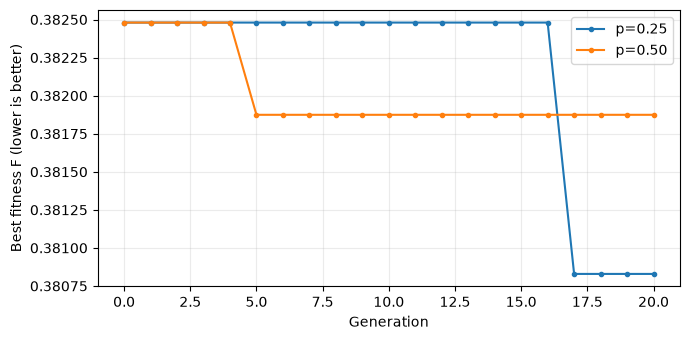

In [20]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    ax.plot(range(len(result["history"])), result["history"], marker=".", label=label)
ax.set(xlabel='Generation', ylabel='Best fitness F (lower is better)')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

Keep your team's interpretation in a text cell: identify the changed parameter; compare best $F$, potable-water use and feasibility; explain a plateau or improvement; and delimit what two executions support. If the results match, explain that agreement. The mutation variation does not need to outperform the baseline.

## 11. Check reproduction

Repeat the baseline with the same seed and check that genes and history match. Restart the kernel and run the notebook from top to bottom to rule out dependence on previous executions. This repetition is a technical check, rather than a third experimental configuration.

In [21]:
repeated = run_ga(**CONFIG)
np.testing.assert_array_equal(baseline["genes"], repeated["genes"])
np.testing.assert_array_equal(baseline["history"], repeated["history"])
assert np.all(np.diff(baseline["history"]) <= 1e-12)
print('Reproduction and elitism checked.')

Reproduction and elitism checked.


## 12. Keep evidence in the same notebook

- **Research (15%)**: A1 formulation and assumptions (60/100); A2 hand calculation and comparison with the evaluator (40/100).
- **Development (15%)**: B1 functional cycle and justified substantive modification of one operator (70/100); B2 reproducibility and controlled baseline/variant comparison (30/100). Use $p_m=0.25$ for both versions.
- **Final (30%)**: C1 explanation of one generation (40/100); C2 same-code comparison of mutation probabilities 0.25/0.50 and its plot (35/100); C3 physical interpretation and model limitations (25/100).

For Final, retain earlier sections and add your team's explanation. Identify the supplied baseline and any team changes. If you still have only the baseline, identify it as unmodified and complete the Final analysis; the Development penalty will not be applied again. Keep the supplied environment files beside the notebook. The written team code examination will contribute 10% and the individual article examination will contribute 30%. Consult the [guide](challenge_guide_planta_fisica.pdf) and the detailed instructions in Canvas for performance levels and dates.

## Provenance and environment

We use the four March 2025 records from the supplied water-consumption data and the instructor-calibrated teaching limits. Notebook metadata retains the records and source hashes. The monthly case and code are self-contained.

With Python 3.12-3.14 and the supplied environment files, prepare the environment with `uv sync --locked` and open Jupyter with `uv run jupyter lab`. NumPy performs the calculations and Matplotlib draws the plot. Results describe this teaching model; they do not establish a validated hydraulic or sanitary recommendation.